# IA102 — Notebook 2 — Entraîner un réseau avec PyTorch

**Durée : 30 minutes** · Objectif visé : **O3** — entraîner des modèles avec PyTorch

Dans scikit-learn, l'optimisation est encapsulée dans `.fit()`. Dans PyTorch, elle est **écrite explicitement**. Cette boucle est identique, à quelques lignes près, pour un réseau de cent paramètres ou de plusieurs milliards.

### La boucle d'entraînement

| # | Étape | Code |
| --- | --- | --- |
| 1 | Passe avant : calculer les prédictions | `sortie = modele(X)` |
| 2 | Calculer la perte | `perte = perte_fn(sortie, y)` |
| 3 | Réinitialiser les gradients | `optimiseur.zero_grad()` |
| 4 | Rétropropagation : calculer les gradients | `perte.backward()` |
| 5 | Mise à jour des paramètres | `optimiseur.step()` |

Une **époque** correspond à un passage complet sur les données d'entraînement.

### Plan
1. Écrire la boucle
2. Observer l'apprentissage
3. Le taux d'apprentissage
4. Les optimiseurs : SGD et Adam
5. Une erreur fréquente : l'oubli de `zero_grad()`
6. Application : classification de vins

In [ ]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

Le jeu de données actuel (généré via make_circles de scikit-learn) comprend 600 échantillons répartis en deux classes distinctes disposées sous forme de cercles concentriques dans un espace bidimensionnel. Il est divisé en un ensemble d'entraînement (75 %) et un ensemble de test (25 %). Chaque point possède deux caractéristiques ($X_1, X_2$$X_1, X_2$) et une étiquette binaire ($y \in \{0, 1\}$$y \in \{0, 1\}$).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_circles, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

X, y = make_circles(n_samples=600, noise=0.08, factor=0.45, random_state=0)
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
X_ent, X_test = torch.tensor(X_ent, dtype=torch.float32), torch.tensor(X_test, dtype=torch.float32)
y_ent = torch.tensor(y_ent, dtype=torch.float32).unsqueeze(1)
y_test = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

def nouveau_reseau():
    torch.manual_seed(0)                       # même initialisation pour tous les essais
    return nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 1))

def exactitude(modele, X, y):
    with torch.no_grad():
        return ((modele(X) > 0).float() == y).float().mean().item()

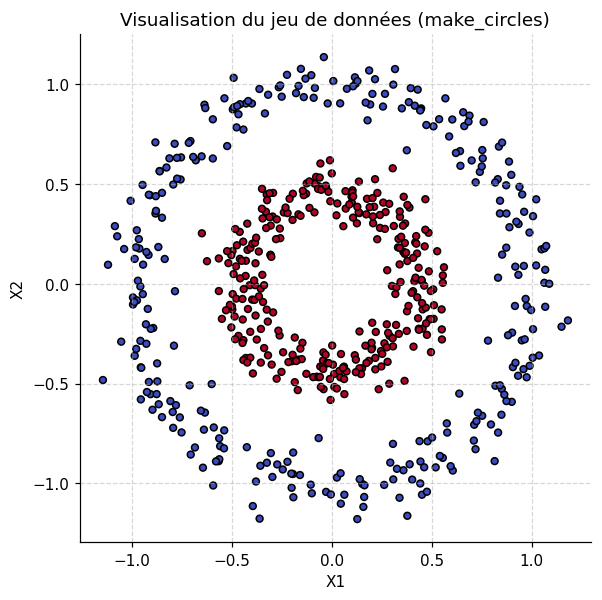

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=20)
plt.title("Visualisation du jeu de données (make_circles)")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 1. Écrire la boucle

### Exercice 4 — Ordonner les étapes de la boucle

Les cinq lignes de la boucle sont listées en désordre dans les commentaires. Placez-les dans le bon ordre à l'intérieur de la boucle.

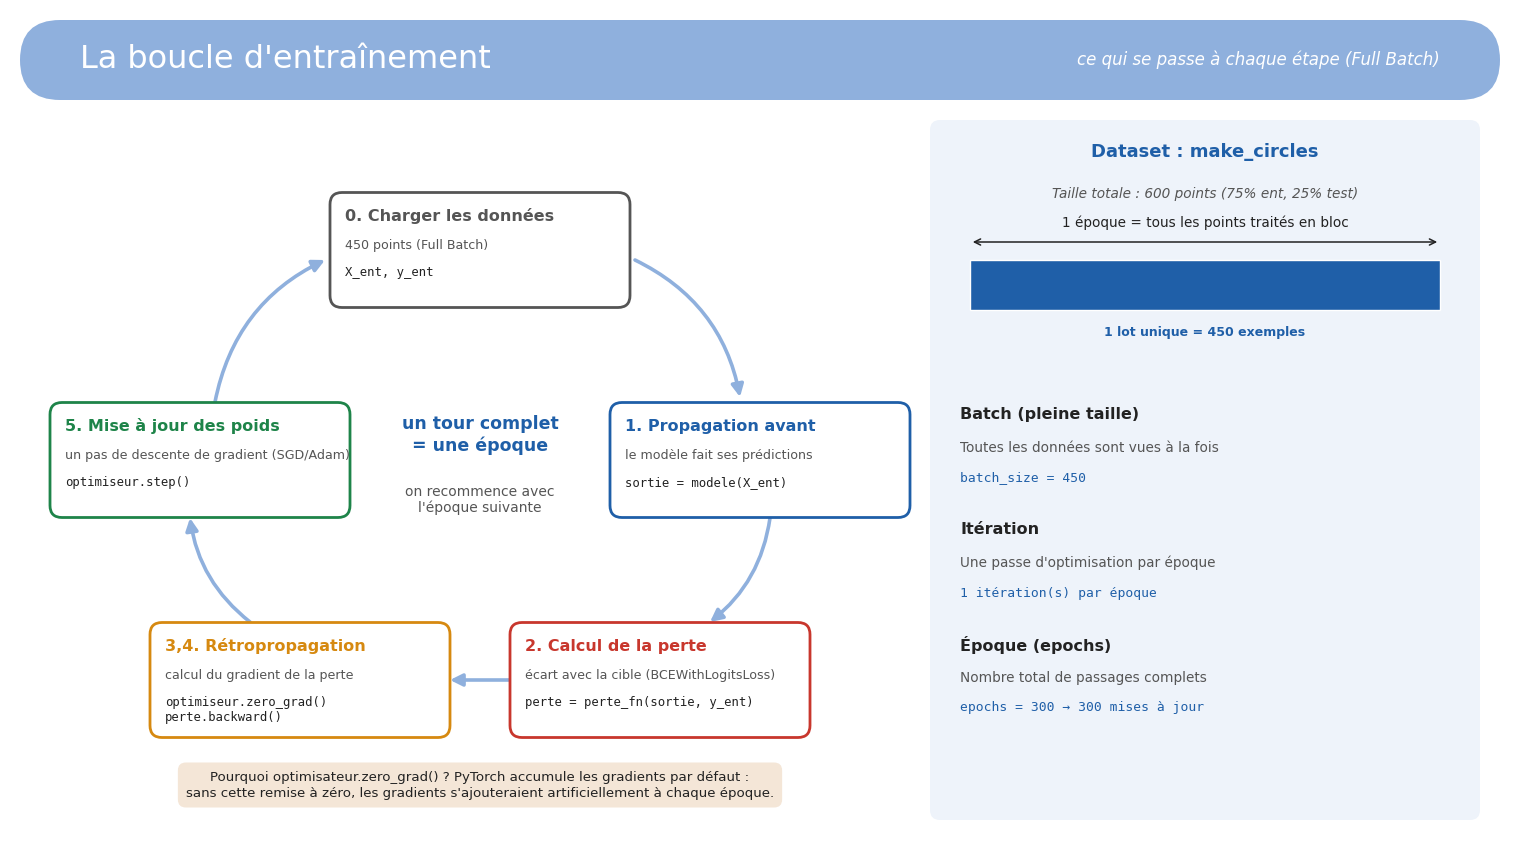

In [4]:
# @title Schéma de la boucle d'entraînement (données du notebook)
import math
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

# Couleurs de la charte des figures
ENCRE, GRIS = "#222222", "#555555"
BLEU, BLEU_CLAIR, FOND = "#1f5fa8", "#8fb0dd", "#eef3fa"
ROUGE, VERT, ORANGE, BEIGE = "#c8372d", "#1e8449", "#d68910", "#f4e6d7"

def milliers(n):
    return f"{n:,}".replace(",", " ")

def fleche(ax, depart, arrivee, rad=0.0):
    ax.add_patch(FancyArrowPatch(depart, arrivee, arrowstyle="-|>", mutation_scale=18, color=BLEU_CLAIR,
                                 lw=2.6, shrinkA=0, shrinkB=0, zorder=2, connectionstyle=f"arc3,rad={rad}"))

def boite(ax, x, y, l, h, couleur):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1.2",
                                fc="white", ec=couleur, lw=2, zorder=3))

def encadre(ax, x, y, l, h):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1",
                                fc=FOND, ec="none", zorder=1))

# Réglages adaptés au dataset make_circles (Full Batch, 450 échantillons d'entraînement)
n_points = 450
batch_size = 450
num_epochs = 300
lots_par_epoque = 1
total_iterations = lots_par_epoque * num_epochs

# Fond de la figure
fig = plt.figure(figsize=(15, 8.4))
f = fig.add_axes([0, 0, 1, 1])
f.set_xlim(0, 150); f.set_ylim(0, 84); f.axis("off")
f.add_patch(FancyBboxPatch((1, 75), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
f.text(7, 79, "La boucle d'entraînement", color="white", fontsize=23, va="center")
f.text(143, 79, "ce qui se passe à chaque étape (Full Batch)", color="white", fontsize=12,
       va="center", ha="right", style="italic")

# Les 5 étapes d'une itération adaptée au code de notre boucle
etapes = [
    ("0. Charger les données", f"{n_points} points (Full Batch)", "X_ent, y_ent", GRIS),
    ("1. Propagation avant", "le modèle fait ses prédictions", "sortie = modele(X_ent)", BLEU),
    ("2. Calcul de la perte", "écart avec la cible (BCEWithLogitsLoss)", "perte = perte_fn(sortie, y_ent)", ROUGE),
    ("3,4. Rétropropagation", "calcul du gradient de la perte", "optimiseur.zero_grad()\nperte.backward()", ORANGE),
    ("5. Mise à jour des poids", "un pas de descente de gradient (SGD/Adam)", "optimiseur.step()", VERT),
]

cx, cy = 47, 39
centres = [(47, 60), (75, 39), (65, 17), (29, 17), (19, 39)]
L, H = 30, 11.5
for (x, y), (titre, detail, ligne, c) in zip(centres, etapes):
    boite(f, x - L / 2, y - H / 2, L, H, c)
    f.text(x - L / 2 + 1.5, y + 3.4, titre, fontsize=11.5, fontweight="bold", color=c, va="center")
    f.text(x - L / 2 + 1.5, y + .4, detail, fontsize=9.1, color=GRIS, va="center")
    f.text(x - L / 2 + 1.5, y - 1.6, ligne, fontsize=8.8, family="monospace", color=ENCRE, va="top", linespacing=1.2)

for dep, arr, rad in (((62.5, 59), (73, 45.3), -.25), ((76, 33.2), (70, 22.8), -.2), ((50, 17), (44, 17), 0),
                      ((24, 22.8), (18, 33.2), -.2), ((20.5, 44.8), (31.5, 59), -.25)):
    fleche(f, dep, arr, rad=rad)

f.text(cx, cy + 2.5, "un tour complet\n= une époque", ha="center", va="center", fontsize=12.5,
       fontweight="bold", color=BLEU, linespacing=1.2)
f.text(cx, cy - 4, "on recommence avec\nl'époque suivante", ha="center", va="center", fontsize=10, color=GRIS, linespacing=1.2)

# Panneau de droite : lots, itérations, époques
x0 = 92
encadre(f, x0, 3, 55, 70)
f.text(x0 + 27.5, 69.3, "Dataset : make_circles", ha="center", fontsize=13, fontweight="bold", color=BLEU)
f.text(x0 + 27.5, 65.2, f"Taille totale : {milliers(600)} points (75% ent, 25% test)", ha="center", fontsize=9.8, color=GRIS, style="italic")

# Représentation de notre lot de données
by, bh = 54, 5
f.add_patch(plt.Rectangle((x0 + 4, by), 47, bh, fc=BLEU, ec="white", lw=1, zorder=3))
f.text(x0 + 27.5, by - 1.6, f"1 lot unique = {batch_size} exemples", fontsize=9, color=BLEU, va="top", fontweight="bold", ha="center")
f.add_patch(FancyArrowPatch((x0 + 4, by + bh + 1.8), (x0 + 51, by + bh + 1.8), arrowstyle="<->", mutation_scale=11, color=ENCRE, lw=1.1))
f.text(x0 + 27.5, by + bh + 3.3, "1 époque = tous les points traités en bloc", ha="center", fontsize=9.8, color=ENCRE)

defs = [
    ("Batch (pleine taille)", "Toutes les données sont vues à la fois", f"batch_size = {batch_size}"),
    ("Itération", "Une passe d'optimisation par époque", f"{lots_par_epoque} itération(s) par époque"),
    ("Époque (epochs)", "Nombre total de passages complets", f"epochs = {num_epochs} → {milliers(total_iterations)} mises à jour")
]
for i, (terme, sens, exemple) in enumerate(defs):
    yy = 43.5 - i * 11.5
    f.text(x0 + 3, yy, terme, fontsize=11.5, fontweight="bold", color=ENCRE, va="center")
    f.text(x0 + 3, yy - 3.3, sens, fontsize=9.8, color=GRIS, va="center")
    f.text(x0 + 3, yy - 6.3, exemple, fontsize=9.4, family="monospace", color=BLEU, va="center")

# Rappel sous la boucle
f.text(47, 6.5, "Pourquoi optimisateur.zero_grad() ? PyTorch accumule les gradients par défaut :\n"
                "sans cette remise à zéro, les gradients s'ajouteraient artificiellement à chaque époque.",
       ha="center", va="center", fontsize=9.6, color=ENCRE, linespacing=1.3,
       bbox=dict(boxstyle="round,pad=.6", fc=BEIGE, ec="none"))

plt.savefig("boucle_entrainement_cercles.png", dpi=170, facecolor="white")
plt.show()

In [ ]:
modele = nouveau_reseau()
perte_fn = nn.BCEWithLogitsLoss()
optimiseur = torch.optim.SGD(modele.parameters(), lr=0.5)

# Lignes en désordre :
#   perte.backward()
#   optimiseur.step()
#   sortie = modele(X_ent)
#   optimiseur.zero_grad()
#   perte = perte_fn(sortie, y_ent)

historique = []
for epoque in range(300):

    ...   # À COMPLÉTER avec la liste

    historique.append(perte.item())

print(f"Perte : {historique[0]:.3f} -> {historique[-1]:.4f}")
print(f"Exactitude sur le test : {exactitude(modele, X_test, y_test):.0%}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
modele = nouveau_reseau()
perte_fn = nn.BCEWithLogitsLoss()
optimiseur = torch.optim.SGD(modele.parameters(), lr=0.5)

historique = []
for epoque in range(300):
    sortie = modele(X_ent)              # 1. passe avant
    perte = perte_fn(sortie, y_ent)     # 2. perte
    optimiseur.zero_grad()              # 3. réinitialiser les gradients
    perte.backward()                    # 4. rétropropagation
    optimiseur.step()                   # 5. mise à jour
    historique.append(perte.item())

print(f"Perte : {historique[0]:.3f} -> {historique[-1]:.4f}")
print(f"Exactitude sur le test : {exactitude(modele, X_test, y_test):.0%}")
```

</details>

`zero_grad()` peut aussi être placé en tête de boucle : l'essentiel est qu'il précède `backward()`.

## 2. Observer l'apprentissage

On enregistre la frontière de décision à plusieurs moments de l'entraînement.

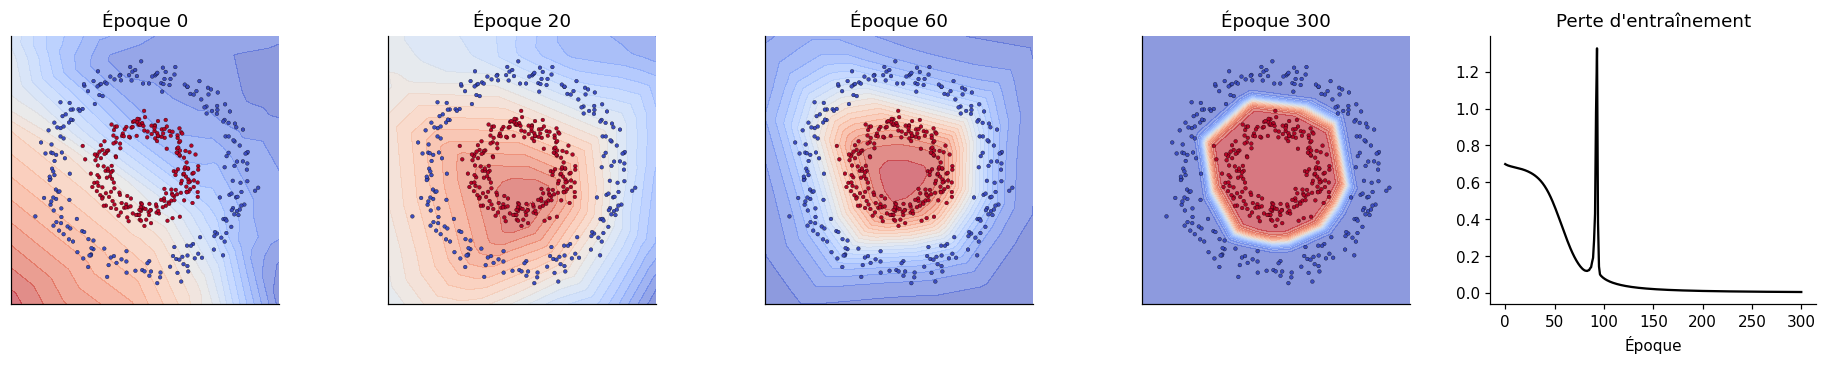

In [ ]:
xx, yy = np.meshgrid(np.linspace(-1.4, 1.4, 200), np.linspace(-1.4, 1.4, 200))
grille = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

modele = nouveau_reseau()
optimiseur = torch.optim.SGD(modele.parameters(), lr=0.5)
perte_fn = nn.BCEWithLogitsLoss()
photos, moments, pertes = [], [0, 20, 60, 300], []
for epoque in range(301):
    if epoque in moments:
        with torch.no_grad():
            photos.append(torch.sigmoid(modele(grille)).numpy().reshape(xx.shape))
    perte = perte_fn(modele(X_ent), y_ent)
    optimiseur.zero_grad(); perte.backward(); optimiseur.step()
    pertes.append(perte.item())

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, photo, moment in zip(axes, photos, moments):
    ax.contourf(xx, yy, photo, levels=20, cmap="coolwarm", alpha=0.6)
    ax.scatter(X_ent[:, 0], X_ent[:, 1], c=y_ent[:, 0], cmap="coolwarm", s=6, edgecolor="k", linewidth=0.2)
    ax.set_title(f"Époque {moment}"); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
axes[4].plot(pertes, color="black"); axes[4].set_title("Perte d'entraînement"); axes[4].set_xlabel("Époque")
plt.tight_layout(); plt.show()

La frontière initiale est arbitraire ; chaque mise à jour la déforme dans le sens qui réduit la perte, jusqu'à épouser la structure circulaire. Le pic visible vers l'époque 90 correspond à un pas momentanément trop grand : la descente de gradient n'est pas toujours monotone.

## 3. Le taux d'apprentissage

**Prédiction.** Avec la descente de gradient (SGD), que se passe-t-il pour des taux de 0,01, 0,5 et 5 ?

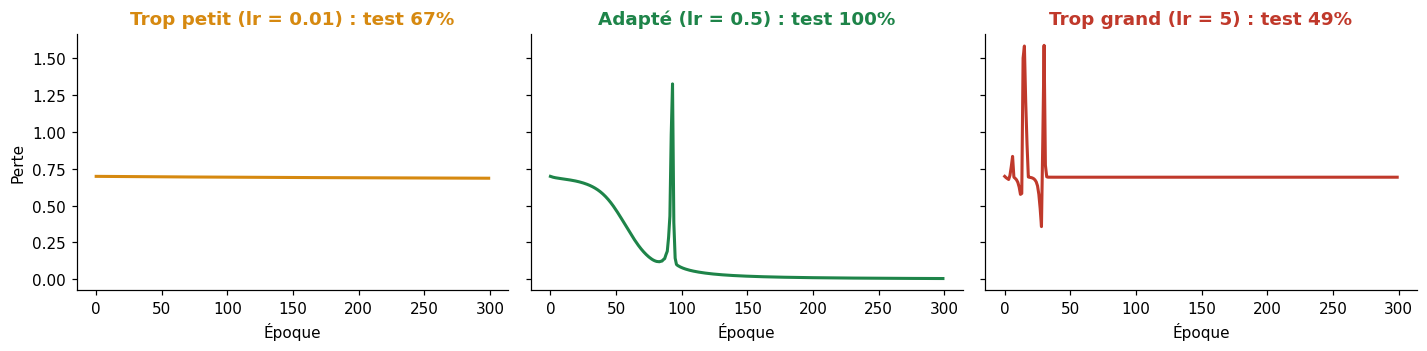

In [ ]:
def entrainer(fabrique_optimiseur, n_epoques=300, reinitialiser_gradients=True):
    modele = nouveau_reseau()
    optimiseur = fabrique_optimiseur(modele.parameters())
    pertes = []
    for epoque in range(n_epoques):
        perte = perte_fn(modele(X_ent), y_ent)
        if reinitialiser_gradients:
            optimiseur.zero_grad()
        perte.backward(); optimiseur.step()
        pertes.append(perte.item())
    return pertes, exactitude(modele, X_test, y_test)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, (lr, titre, c) in zip(axes, [(0.01, "Trop petit", "#d68910"), (0.5, "Adapté", "#1e8449"), (5, "Trop grand", "#c0392b")]):
    p, acc = entrainer(lambda params: torch.optim.SGD(params, lr=lr))
    ax.plot(p, color=c, lw=2); ax.set_title(f"{titre} (lr = {lr}) : test {acc:.0%}", color=c, fontweight="bold"); ax.set_xlabel("Époque")
axes[0].set_ylabel("Perte"); plt.tight_layout(); plt.show()

- **Trop petit :** la perte diminue à peine en 300 époques.
- **Adapté :** la perte chute et le test est réussi.
- **Trop grand :** les premières mises à jour sont si importantes que les neurones ReLU deviennent inactifs (leur entrée reste négative, leur gradient est nul) ; le réseau reste bloqué au niveau du hasard.

## 4. Les optimiseurs : SGD et Adam

- **SGD** applique $\theta \leftarrow \theta - \eta\,\nabla L$.
- **Adam** maintient, pour chaque paramètre, une moyenne mobile des gradients (effet d'inertie) et de leurs carrés (adaptation de l'échelle). Il est moins sensible au choix de $\eta$ et constitue un bon choix par défaut, avec $\eta$ entre $10^{-4}$ et $10^{-2}$.

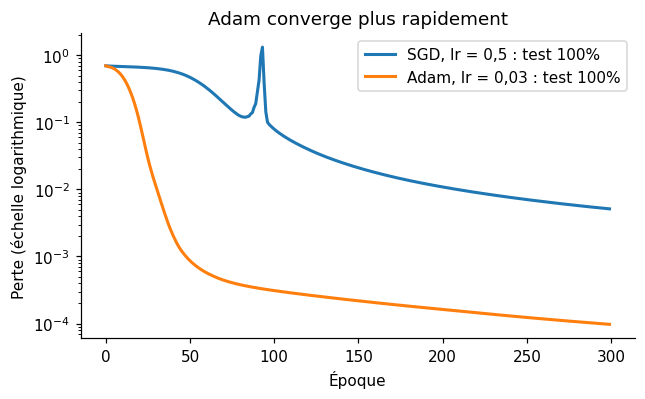

In [ ]:
plt.figure(figsize=(6.5, 3.6))
for nom, fabrique in [("SGD, lr = 0,5", lambda p: torch.optim.SGD(p, lr=0.5)), ("Adam, lr = 0,03", lambda p: torch.optim.Adam(p, lr=0.03))]:
    p, acc = entrainer(fabrique)
    plt.plot(p, lw=2, label=f"{nom} : test {acc:.0%}")
plt.yscale("log"); plt.xlabel("Époque"); plt.ylabel("Perte (échelle logarithmique)")
plt.title("Adam converge plus rapidement"); plt.legend(); plt.show()

## 5. Une erreur fréquente : l'oubli de `zero_grad()`

Par défaut, PyTorch **additionne** les nouveaux gradients à ceux déjà stockés dans `.grad`. Sans réinitialisation, chaque mise à jour utilise la somme de tous les gradients depuis le début de l'entraînement.

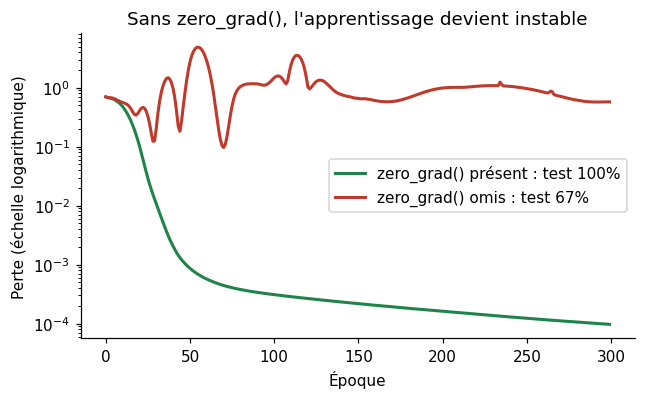

In [ ]:
plt.figure(figsize=(6.5, 3.6))
for reinit, c in [(True, "#1e8449"), (False, "#c0392b")]:
    p, acc = entrainer(lambda params: torch.optim.Adam(params, lr=0.03), reinitialiser_gradients=reinit)
    plt.plot(p, color=c, lw=2, label=f"zero_grad() {'présent' if reinit else 'omis'} : test {acc:.0%}")
plt.yscale("log"); plt.xlabel("Époque"); plt.ylabel("Perte (échelle logarithmique)")
plt.title("Sans zero_grad(), l'apprentissage devient instable"); plt.legend(); plt.show()

## 6. Application : classification de vins

On reprend les vins d'IA101 avec le même découpage. Le KNN normalisé y obtenait 93,3 %.

Rappels :
- 13 variables, 3 classes : couche de sortie `Linear(…, 3)` et `nn.CrossEntropyLoss()` ;
- les étiquettes sont des entiers (`torch.long`) ;
- la classe prédite est `modele(X).argmax(dim=1)`.

### Exercice 5 — Entraîner un réseau sur les vins

In [ ]:
vins = load_wine()
Xv_ent, Xv_test, yv_ent, yv_test = train_test_split(vins.data, vins.target, test_size=0.25, stratify=vins.target, random_state=0)

normaliseur = StandardScaler().fit(Xv_ent)            # estimé sur l'entraînement seulement
Xv_ent = torch.tensor(normaliseur.transform(Xv_ent), dtype=torch.float32)
Xv_test = torch.tensor(normaliseur.transform(Xv_test), dtype=torch.float32)
yv_ent, yv_test = torch.tensor(yv_ent), torch.tensor(yv_test)

torch.manual_seed(0)
reseau_vin = nn.Sequential(...)        # À COMPLÉTER : 13 -> 32 -> ReLU -> 3 nn.Linear(..., ...), nn.ReLU(), nn.Linear(..., ...)
perte_vin = ...                        # À COMPLÉTER nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(reseau_vin.parameters(), lr=0.01)

for epoque in range(200):
    ...                                # À COMPLÉTER : les cinq étapes

with torch.no_grad():
    exact_vin = (reseau_vin(Xv_test).argmax(dim=1) == yv_test).float().mean().item()
print(f"Exactitude du réseau sur les vins : {exact_vin:.1%} (KNN normalisé, IA101 : 93,3 %)")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
vins = load_wine()
Xv_ent, Xv_test, yv_ent, yv_test = train_test_split(vins.data, vins.target, test_size=0.25, stratify=vins.target, random_state=0)

normaliseur = StandardScaler().fit(Xv_ent)
Xv_ent = torch.tensor(normaliseur.transform(Xv_ent), dtype=torch.float32)
Xv_test = torch.tensor(normaliseur.transform(Xv_test), dtype=torch.float32)
yv_ent, yv_test = torch.tensor(yv_ent), torch.tensor(yv_test)

torch.manual_seed(0)
reseau_vin = nn.Sequential(nn.Linear(13, 32), nn.ReLU(), nn.Linear(32, 3))
perte_vin = nn.CrossEntropyLoss()
optimiseur = torch.optim.Adam(reseau_vin.parameters(), lr=0.01)

for epoque in range(200):
    sortie = reseau_vin(Xv_ent)
    perte = perte_vin(sortie, yv_ent)
    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

with torch.no_grad():
    exact_vin = (reseau_vin(Xv_test).argmax(dim=1) == yv_test).float().mean().item()
print(f"Exactitude du réseau sur les vins : {exact_vin:.1%} (KNN normalisé, IA101 : 93,3 %)")
```

</details>

Sur un petit jeu tabulaire (45 vins en test), l'écart avec le KNN reste peu significatif : une seule erreur représente plus de 2 points. Les réseaux de neurones prennent l'avantage sur les **données brutes et volumineuses**, comme les images (notebook 3).

### Bonnes pratiques
- `modele.train()` avant l'entraînement et `modele.eval()` avant l'évaluation : certaines couches (dropout, normalisation par lots) se comportent différemment dans les deux modes.
- `with torch.no_grad():` pendant l'évaluation : le graphe de calcul n'est pas enregistré, ce qui économise mémoire et temps.
- Fixer la graine (`torch.manual_seed`) pour rendre les expériences reproductibles.

In [ ]:
quiz("Dans quel ordre faut-il appeler perte.backward() et optimiseur.step() ?",
     ["step() puis backward()", "backward() puis step()", "L'ordre est indifférent"],
     1, "backward() calcule les gradients ; step() les utilise pour mettre à jour les paramètres.")

In [ ]:
quiz("Avec SGD et lr = 5, la perte reste bloquée dès les premières époques. Quelle action est appropriée ?",
     ["Augmenter le taux d'apprentissage", "Réduire le taux d'apprentissage ou utiliser Adam", "Supprimer zero_grad()"],
     1, "Un pas trop grand peut rendre les neurones ReLU inactifs ou faire diverger l'apprentissage.")

## À retenir

```python
for epoque in range(n_epoques):
    sortie = modele(X)               # 1. passe avant
    perte = perte_fn(sortie, y)      # 2. perte
    optimiseur.zero_grad()           # 3. réinitialiser les gradients
    perte.backward()                 # 4. rétropropagation
    optimiseur.step()                # 5. mise à jour
```

- Le **taux d'apprentissage** est le réglage le plus déterminant.
- **Adam** est un bon optimiseur par défaut.
- Sans `zero_grad()`, les gradients s'accumulent et l'apprentissage devient instable.

**Pause de 10 minutes.** Notebook suivant : 3 — Réseaux convolutifs.